# 01 - Exploration des données (CIC-IDS2017)

Objectif : comprendre le dataset avant de modéliser.

In [1]:
import sys; sys.path.append('..')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.load_data import find_csv_files, load_day



files = find_csv_files()


for f in files: print(f.name)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


## 1. Charger un fichier
On commence avec le mercredi (attaques DoS). Change `nrows` en `None` pour tout charger.

In [2]:
path = next(f for f in files if 'Wednesday' in f.name)
df = load_day(path, nrows=200_000)

print(df.shape)
df.head()

(170800, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## 2. Distribution des classes
Le trafic normal domine : l'accuracy seule sera trompeuse.

Label
DoS Hulk            91922
BENIGN              68265
DoS slowloris        5385
DoS Slowhttptest     5228
Name: count, dtype: int64


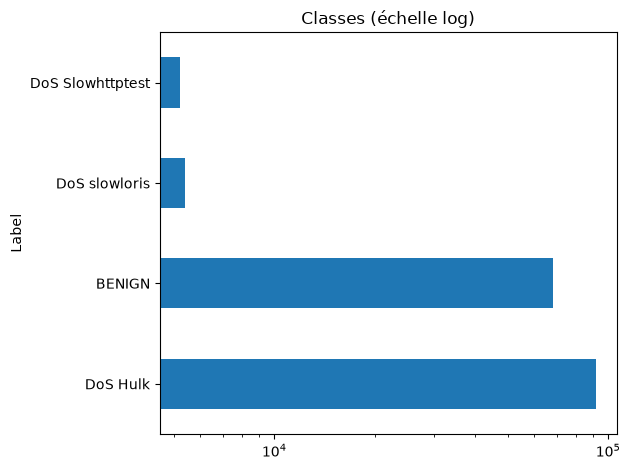

In [3]:
counts = df['Label'].value_counts()
print(counts)

counts.plot(kind='barh', logx=True, title='Classes (échelle log)')
plt.tight_layout(); plt.savefig('../results/class_distribution.png', dpi=150)

## 3. Valeurs manquantes et types

In [4]:
print(df.isna().sum().sum(), 'valeurs manquantes')
df.dtypes.value_counts()


0 valeurs manquantes


int64      54
float64    24
str         1
Name: count, dtype: int64

## 4. Statistiques des features

In [5]:
df.describe().T.head(20)


,count,mean,std,min,25%,50%,75%,max
Destination Port,170800.0,3.185311e+03,1.170969e+04,0.0,80.000000,8.000000e+01,8.000000e+01,6.500200e+04
Flow Duration,170800.0,5.299886e+07,4.632437e+07,-1.0,144685.000000,8.192399e+07,9.838538e+07,1.200000e+08
Total Fwd Packets,170800.0,2.087081e+01,1.498999e+03,1.0,3.000000,6.000000e+00,8.000000e+00,2.039430e+05
Total Backward Packets,170800.0,2.457889e+01,1.973316e+03,0.0,2.000000,6.000000e+00,7.000000e+00,2.723530e+05
Total Length of Fwd Packets,170800.0,8.076137e+02,9.902240e+03,0.0,70.000000,3.480000e+02,4.050000e+02,1.224076e+06
Total Length of Bwd Packets,170800.0,4.971468e+04,4.496787e+06,0.0,102.000000,1.159500e+04,1.159500e+04,6.270000e+08
Fwd Packet Length Max,170800.0,3.624535e+02,7.162134e+02,0.0,50.000000,3.280000e+02,3.670000e+02,2.482000e+04
Fwd Packet Length Min,170800.0,8.278126e+00,4.283481e+01,0.0,0.000000,0.000000e+00,0.000000e+00,1.983000e+03
Fwd Packet Length Mean,170800.0,8.627888e+01,1.901868e+02,0.0,39.000000,5.214286e+01,7.811111e+01,4.640758e+03
Fwd Packet Length Std,170800.0,1.412032e+02,2.724781e+02,0.0,3.464102,1.250974e+02,1.574478e+02,6.429191e+03


## 5. Corrélations
Les features très corrélées sont redondantes.

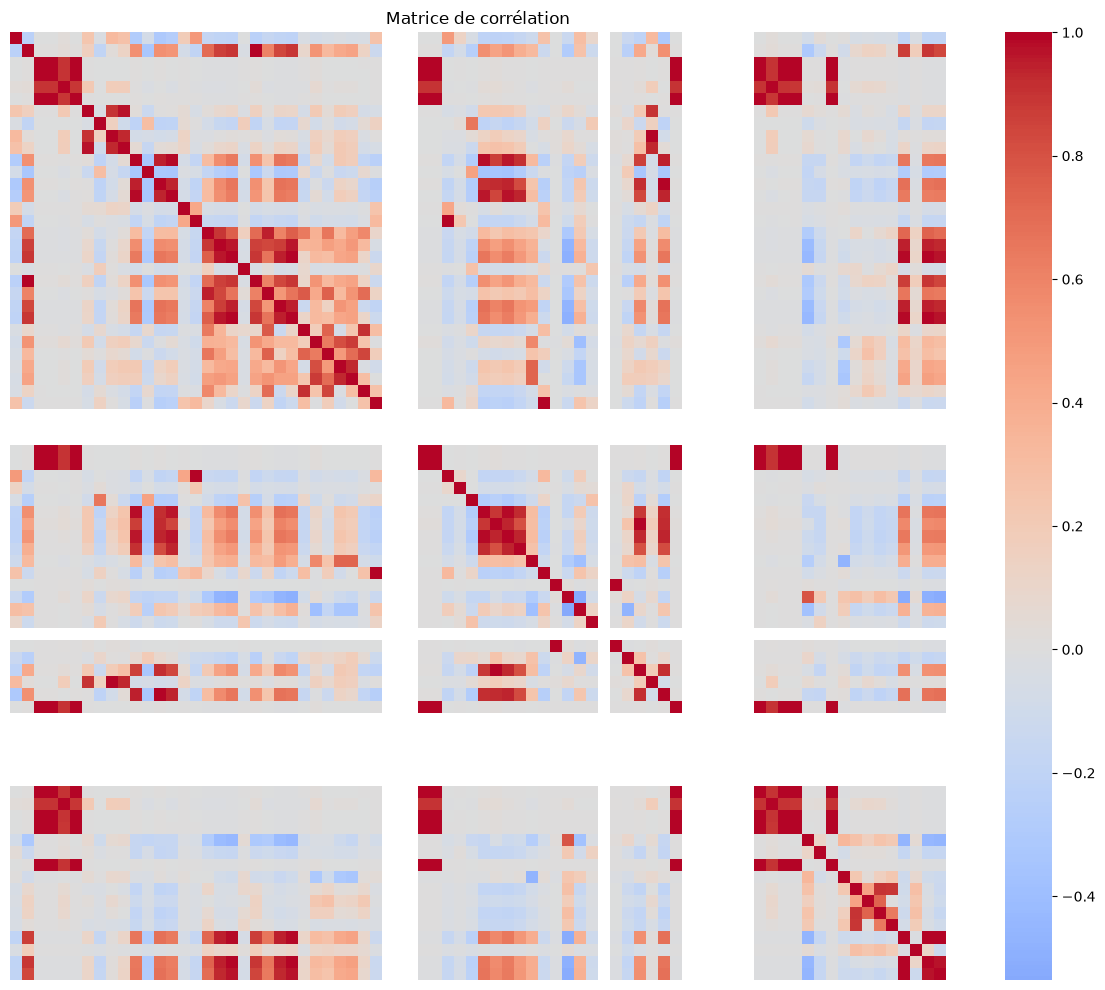

In [6]:
num = df.select_dtypes('number')
corr = num.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('Matrice de corrélation'); plt.tight_layout()
plt.savefig('../results/correlation.png', dpi=150)

## Observations
*(à compléter par toi : quelles classes sont rares ? quelles features semblent discriminantes ?)*

## Observations
- Les classes : BENIGN et DoS Hulk sont les plus nombreuses, slowloris et Slowhttptest sont rares.
- Certaines colonnes (Flow Bytes/s, Flow Packets/s, Flow IAT Min) ont des valeurs négatives, ce qui est impossible : ce sont des erreurs du dataset à corriger.
- Les valeurs sont très étalées (de 0 à des millions) : il faudra normaliser.
- La matrice de corrélation montre des groupes de colonnes très corrélées, donc redondantes.